#### Importação das bibliotecas ####

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


#### Carregando o dataset ####

In [13]:
df = pd.read_csv("data/bbc-text.csv")

print("Dataset carregado com sucesso!")

df.head()

Dataset carregado com sucesso!


,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


#### Definindo as features ####

A coluna 'category' serve mais como target do que como feature, então vamos utilizar apenas o 'text'.

In [14]:
X = df['text']

print("Features definidas.")

Features definidas.


#### TF-IDF ####

In [ ]:
vectorizer = TfidfVectorizer() # criando o vetorizador

tfidf_matrix = vectorizer.fit_transform(X) # transformando os textos das features em vetor para cada documento

print("Textos vetorizados com sucesso!")

Textos vetorizados com sucesso!


O 'tfidf_matrix' retorna uma matriz esparsa, e por isso é necessário utilizar a função '.toarray()' para conseguirmos visualizá-la.

In [16]:
print(tfidf_matrix.toarray())

[[0.         0.01653311 0.         ... 0.         0.         0.        ]
 [0.         0.02288915 0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]
 ...
 [0.         0.02438145 0.         ... 0.         0.         0.        ]
 [0.         0.01314914 0.         ... 0.         0.         0.        ]
 [0.         0.         0.         ... 0.         0.         0.        ]]


Função responsável pelo cálculo das fusões dos clusters.

Recebe os dados vetorizados e um método de "ligação" que define como medir a distância entre dois clusters.

In [17]:
linkage_matrix = linkage(tfidf_matrix.toarray(), method='ward', metric='euclidean', optimal_ordering=False)

#### Dendrograma ####

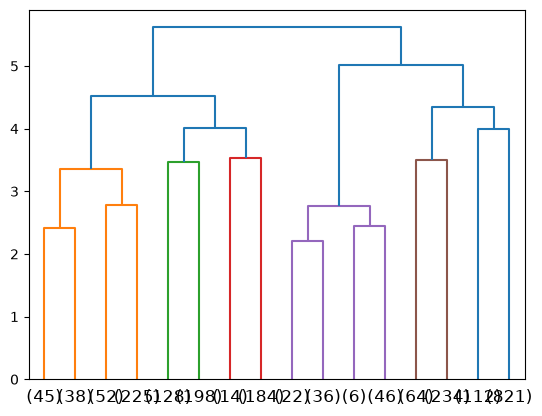

In [ ]:
dendrograma = dendrogram(Z=linkage_matrix, p=3, truncate_mode='level') # o 'p' representa o limite máximo de fusões a serem exibidas por galho

Os números do eixo 'x' representa a quantidade de galhos que estão escondidos por causa do 'truncate_mode'.

Quanto mais alto dois galhos se juntam, mais diferentes eram os grupos que estão sendo unidos ali.]

Para cortar, você traça uma linha horizontal imaginária no gráfico, toda vez que essa linha cruza uma linha vertical do dendrograma, isso vira um cluster. Quanto mais baixo, mais clusters, ou seja, junta menos coisas.

Geralmente você procura cortar numa altura onde existe um "salto grande" antes da próxima fusão, ou seja, onde os clusters que já se formaram são bem diferentes dos próximos a se juntar.

#### Treinamento do modelo ####

Foi utilizado o Clustering Aglomerativo.

Foram utilizados 5 clusters, que são a quantidade de categorias no nosso dataset.

In [ ]:
model = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
cluster_labels = model.fit_predict(tfidf_matrix.toarray())

#### Avaliando a performance do nosso modelo ####

In [ ]:
tabela = pd.crosstab(df['category'], cluster_labels)
tabela

col_0,0,1,2,3,4
category,,,,,
business,10,487,2,4,7
entertainment,17,27,0,328,14
politics,2,286,108,16,5
sport,491,16,0,4,0
tech,4,117,0,8,272


: 

O eixo 'x' representa o número de cada cluster e o 'y' as categorias possíveis no nosso dataset.

Os valores representam a quantidade de cada categoria agrupada em cada um dos clusters.

#### Conclusão ####

Cluster 0: dominado por sport, 491 dos 511 documentos estão nesse cluster.

Cluster 1: cluster bem bagunçado com números bem variados de cada uma das categorias, mas sua maioria sendo de 'business'.

Cluster 2: tem praticamente apenas documentos de 'politics', mas em compensação, possui uma grande minoria do total desses dados, apenas 108 dos 417 documentos.

Cluster 3: predominado pela categoria 'entertainment' com 328 dos 386 documentos totais e poucos das demais categorias.

Cluster 4: dominado por 'tech' em que dos 298 documentos no cluster, 272 são dessa categoria.